In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import PIL
import tensorflow as tf
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from concurrent.futures import ThreadPoolExecutor
from collections import Counter

I0000 00:00:1791294621.472432   16268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791294621.667425   16268 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791294623.110869   16268 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print("Devices: ", tf.config.list_physical_devices())

Num GPUs Available:  1
Devices:  [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
Base_Directory = 'dataset/'
image_size =(180,180)
batch_s = 16
epochs = 20

Data Preprocessing

In [4]:
folders = [
    "dataset/Painting/",
    "dataset/Photo/",
    "dataset/Schematics/",
    "dataset/Sketch/",
    "dataset/Text/",
]

extensions = {".jpg", ".jpeg", ".png"}
bad_files = []
counts = Counter()


def check_image(path):
    try:
        with Image.open(path) as img:
            img.verify()
        return (str(path), None)
    except Exception as e:
        return (str(path), str(e))


# Collect image paths
paths = [
    p
    for folder in folders
    for p in Path(folder).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print(f"Found {len(paths)} images.")

# Verify using multiple threads
with ThreadPoolExecutor(max_workers=4) as executor:
    for i, (path, error) in enumerate(executor.map(check_image, paths), start=1):
        if error:
            bad_files.append((path, error))
        else:
            counts["valid"] += 1

        if i % 500 == 0 or i == len(paths):
            print(f"Checked {i}/{len(paths)} images")

print(f"Valid images: {counts['valid']}")
print(f"Bad images: {len(bad_files)}")

for path, error in bad_files:
    print(f"{path}: {error}")

Found 41398 images.
Checked 500/41398 images
Checked 1000/41398 images
Checked 1500/41398 images
Checked 2000/41398 images
Checked 2500/41398 images
Checked 3000/41398 images
Checked 3500/41398 images
Checked 4000/41398 images
Checked 4500/41398 images
Checked 5000/41398 images
Checked 5500/41398 images
Checked 6000/41398 images
Checked 6500/41398 images
Checked 7000/41398 images
Checked 7500/41398 images
Checked 8000/41398 images
Checked 8500/41398 images
Checked 9000/41398 images
Checked 9500/41398 images
Checked 10000/41398 images
Checked 10500/41398 images
Checked 11000/41398 images
Checked 11500/41398 images
Checked 12000/41398 images
Checked 12500/41398 images
Checked 13000/41398 images
Checked 13500/41398 images
Checked 14000/41398 images
Checked 14500/41398 images
Checked 15000/41398 images
Checked 15500/41398 images
Checked 16000/41398 images
Checked 16500/41398 images
Checked 17000/41398 images
Checked 17500/41398 images
Checked 18000/41398 images
Checked 18500/41398 images
C

In [5]:
import math

train_set = tf.keras.preprocessing.image_dataset_from_directory(
  Base_Directory,
  validation_split= 0.2,
  subset="training",
  seed=42,
  batch_size=batch_s,
  image_size=image_size,
  shuffle=False
)

# The test_set
test_set = tf.keras.preprocessing.image_dataset_from_directory(
  Base_Directory,
  validation_split= 0.2,
  subset="training",
  seed=42,
  batch_size=batch_s,
  image_size=image_size
)

Found 41398 files belonging to 5 classes.
Using 33119 files for training.


I0000 00:00:1791294626.609614   16268 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6282 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 41398 files belonging to 5 classes.
Using 33119 files for training.


In [6]:
class_names =  train_set.class_names
print(class_names)

['Painting', 'Photo', 'Schematics', 'Sketch', 'Text']


dataset/


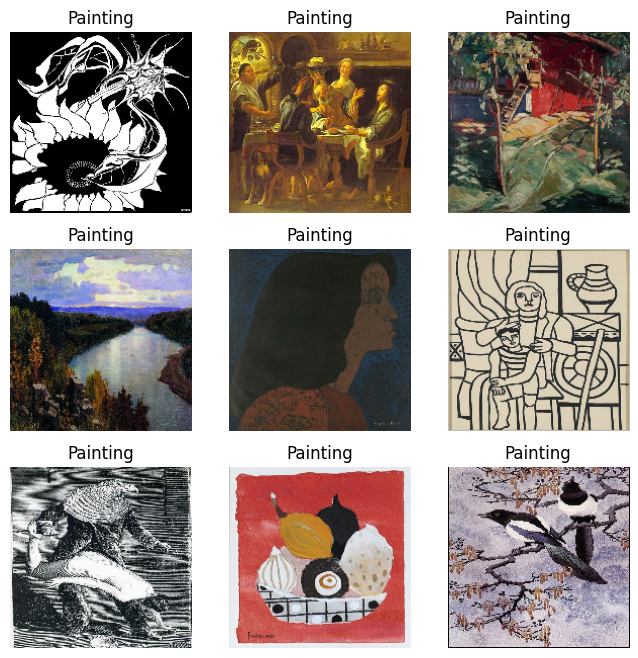

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
for images, labels in train_set.take(1):
    for i in range(9):
        ax =  plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype('uint8'))
        plt.title(class_names[labels[i]])
        plt.axis("off")

print(Base_Directory)

In [8]:
AUTOTUNE = tf.data.experimental.AUTOTUNE


train_set = train_set.cache("/mnt/ai/training_cache/").shuffle(1000,reshuffle_each_iteration=True).prefetch(buffer_size=AUTOTUNE)#prefetch can be "buffer_size=AUTOTUNE" or 1
test_set = test_set.cache("/mnt/ai/training_cache/").prefetch(buffer_size=AUTOTUNE)# prefetch "buffer_size=AUTOTUNE"
# .ignore_errors()
# try prefetch 1 to see if it help with memory problem

In [9]:
num_classes = 5 # Number of classes and therefore also number of neurons in the last layer
model = Sequential()

In [10]:
data_augmentation = keras.Sequential(
  [
    layers.RandomFlip(mode="horizontal"),
    #layers.RandomRotation(factor=(-0.1,0.1)),
    #layers.RandomZoom(height_factor=(-0.1,0.1),width_factor=(-0.1,0.1),),
  ]
)

need to explain : the network parameters, the loss function and the optimization algorithm used for training

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 80)             │     2,478,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,502,149 (9.54 MB)

 Trainable params: 2,502,149 (9.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (6 outputs left out)

I0000 00:00:1791295265.633068   21374 shuffle_dataset_op.cc:453] ShuffleDatasetV3:15: Filling up shuffle buffer (this may take a while): 611 of 1000


  16/2070 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.9484 - loss: 0.1484

I0000 00:00:1791295270.099806   21374 shuffle_dataset_op.cc:483] Shuffle buffer filled.


2070/2070 ━━━━━━━━━━━━━━━━━━━━ 51s 18ms/step - accuracy: 0.9598 - loss: 0.1124 - val_accuracy: 0.9625 - val_loss: 0.1066
Epoch 15/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9632 - loss: 0.0998 - val_accuracy: 0.9751 - val_loss: 0.0702
Epoch 16/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9696 - loss: 0.0859 - val_accuracy: 0.9725 - val_loss: 0.0764
Epoch 17/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9737 - loss: 0.0757 - val_accuracy: 0.9796 - val_loss: 0.0589
Epoch 18/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9769 - loss: 0.0672 - val_accuracy: 0.9781 - val_loss: 0.0678
Epoch 19/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9759 - loss: 0.0718 - val_accuracy: 0.9705 - val_loss: 0.0784
Epoch 20/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 46s 18ms/step - accuracy: 0.9816 - loss: 0.0526 - val_accuracy: 0.9868 - val_loss: 0.0406


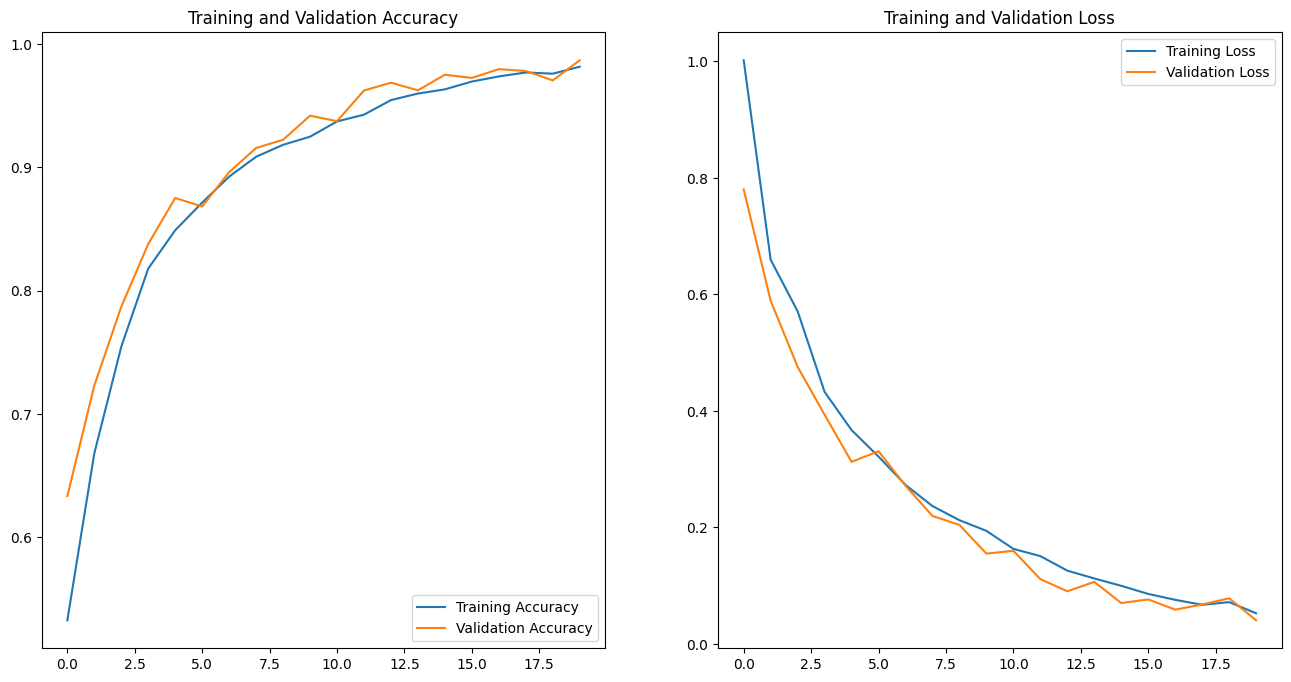

In [11]:

image_h,image_w=image_size
complete_model = keras.models.Sequential(
    [
        layers.InputLayer(shape=(image_h,image_w,3)),
        data_augmentation,
        layers.Rescaling(scale=1.0/255),
        layers.Conv2D(16,(3,3),padding="same",activation="relu"),
        layers.MaxPool2D(),
        layers.Conv2D(32,(3,3),padding="same",activation="relu"),
        layers.MaxPool2D(),
        layers.Conv2D(64,(3,3),padding="same",activation="relu"),
        layers.MaxPool2D(),
        layers.Flatten(data_format=None),
        layers.Dense(80, activation='relu'),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

complete_model.compile(optimizer ="adam",
              loss = "sparse_categorical_crossentropy",
              metrics=['accuracy'])
complete_model.summary()

history =  complete_model.fit(
    train_set,
    validation_data=test_set,
    epochs=epochs
)

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

explain theses results of the graph : #todo

explain the trade-off between bias and variance (or overlearning and underlearning)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 80)             │     2,478,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,502,149 (9.54 MB)

 Trainable params: 2,502,149 (9.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (6 outputs left out)

I0000 00:00:1791296301.118036   26640 shuffle_dataset_op.cc:483] Shuffle buffer filled.


2070/2070 ━━━━━━━━━━━━━━━━━━━━ 48s 18ms/step - accuracy: 0.9676 - loss: 0.0903 - val_accuracy: 0.9811 - val_loss: 0.0596
Epoch 17/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 47s 18ms/step - accuracy: 0.9716 - loss: 0.0784 - val_accuracy: 0.9696 - val_loss: 0.0813
Epoch 18/20
   1/2070 ━━━━━━━━━━━━━━━━━━━━ 5:50:42 10s/step - accuracy: 1.0000 - loss: 0.0237

I0000 00:00:1791296395.701935   27134 shuffle_dataset_op.cc:453] ShuffleDatasetV3:15: Filling up shuffle buffer (this may take a while): 986 of 1000
I0000 00:00:1791296395.855666   27134 shuffle_dataset_op.cc:483] Shuffle buffer filled.


2070/2070 ━━━━━━━━━━━━━━━━━━━━ 49s 19ms/step - accuracy: 0.9726 - loss: 0.0759 - val_accuracy: 0.9828 - val_loss: 0.0491
Epoch 19/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 48s 18ms/step - accuracy: 0.9765 - loss: 0.0675 - val_accuracy: 0.9779 - val_loss: 0.0659
Epoch 20/20
2070/2070 ━━━━━━━━━━━━━━━━━━━━ 48s 19ms/step - accuracy: 0.9777 - loss: 0.0679 - val_accuracy: 0.9900 - val_loss: 0.0300


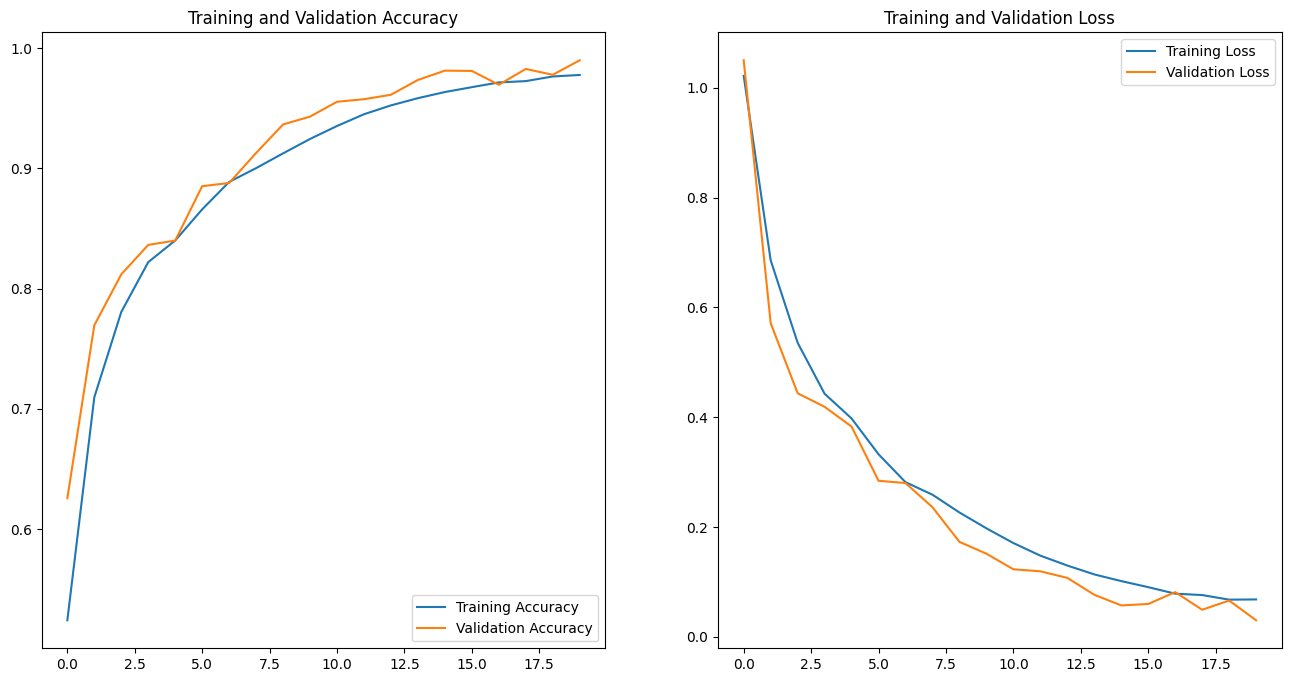

In [12]:
model_with_dropout = keras.Sequential(
    [
        layers.Input(shape=(image_size[0], image_size[1], 3)),
        data_augmentation,
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.2),
        layers.Flatten(),
        layers.Dense(80,activation="relu"),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

# Compiling the model
model_with_dropout.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Model Summary
model_with_dropout.summary()

# Model training
history = model_with_dropout.fit(
    train_set,
    validation_data=test_set,
    epochs=epochs,
)
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(epochs)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.show()

why this result is better 

In [18]:
model_with_dropout.save_weights("model_with_dropout.weights.h5")